In [2]:
import kagglehub
path = kagglehub.dataset_download("leilahasan/pedestrian-counts")
print("Path to dataset files:", path)

100%|██████████| 2.57M/2.57M [00:01<00:00, 2.62MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/leilahasan/pedestrian-counts/versions/1


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
file_path=f"{path}/pedestrian-counts-1-jan-31-december-2023 (2).csv"
df = pd.read_csv(file_path)
print("Dataset loaded successfully!")
print("Number of rows and columns",df.shape)
print(df.head())

Dataset loaded successfully!
Number of rows and columns (8760, 115)
               Time  Aston Quay/Fitzgeralds  Aston Quay/Fitzgeralds IN  \
0  01/01/2023 00:00                  3700.0                     1455.0   
1  01/01/2023 01:00                  4369.0                     2142.0   
2  01/01/2023 02:00                  3807.0                     2031.0   
3  01/01/2023 03:00                  2477.0                     1352.0   
4  01/01/2023 04:00                  1534.0                      836.0   

   Aston Quay/Fitzgeralds OUT  Bachelors walk/Bachelors way  \
0                      2245.0                           0.0   
1                      2227.0                           0.0   
2                      1776.0                           0.0   
3                      1125.0                           0.0   
4                       698.0                           0.0   

   Bachelors walk/Bachelors way IN  Bachelors walk/Bachelors way OUT  \
0                              0.0  

In [4]:
print("Column Names",df.columns.tolist())
print("\nDataset Information:")
df.info()

Column Names ['Time', 'Aston Quay/Fitzgeralds', 'Aston Quay/Fitzgeralds IN', 'Aston Quay/Fitzgeralds OUT', 'Bachelors walk/Bachelors way', 'Bachelors walk/Bachelors way IN', 'Bachelors walk/Bachelors way OUT', 'Baggot st lower/Wilton tce inbound', 'Baggot st lower/Wilton tce inbound Pedestrians IN', 'Baggot st lower/Wilton tce inbound Pedestrians OUT', 'Baggot st upper/Mespil rd/Bank', 'Baggot st upper/Mespil rd/Bank Pedestrians IN', 'Baggot st upper/Mespil rd/Bank Pedestrians OUT', 'Capel st/Mary street', 'Capel st/Mary street Pedestrian IN', 'Capel st/Mary street Pedestrian OUT', 'College Green/Bank Of Ireland', 'College Green/Bank Of Ireland IN', 'College Green/Bank Of Ireland OUT', 'College Green/Church Lane', 'College Green/Church Lane IN', 'College Green/Church Lane OUT', 'College st/Westmoreland st', 'College st/Westmoreland st IN', 'College st/Westmoreland st OUT', "D'olier st/Burgh Quay", "D'olier st/Burgh Quay IN", "D'olier st/Burgh Quay OUT", 'Dame Street/Londis', 'Dame Stre

In [5]:
print("Missing values in each column")
print(df.isnull().sum())

Missing values in each column
Time                                            0
Aston Quay/Fitzgeralds                          1
Aston Quay/Fitzgeralds IN                       1
Aston Quay/Fitzgeralds OUT                      1
Bachelors walk/Bachelors way                 1364
                                             ... 
Westmoreland Street East/Fleet street IN     2425
Westmoreland Street East/Fleet street OUT    2425
Westmoreland Street West/Carrolls            6169
Westmoreland Street West/Carrolls IN         6169
Westmoreland Street West/Carrolls OUT        6169
Length: 115, dtype: int64


In [6]:
print("Duplicated rows:",df.duplicated().sum())

Duplicated rows: 0


In [7]:
print("Total Missing values",df.isnull().sum().sum())

Total Missing values 282774


In [8]:
print("Missing values in selected columns:")
columns=['Bachelors walk/Bachelors way','Westmoreland Street West/Carrolls']
print(df[columns].isnull().sum())

Missing values in selected columns:
Bachelors walk/Bachelors way         1364
Westmoreland Street West/Carrolls    6169
dtype: int64


In [9]:
df_clean=df.dropna(subset=columns).copy()
print("Original dataset shape: ",df.shape)
print("Cleaned dataset shape: ",df_clean.shape)
print("\nFirst 5 rows of Cleaned dataset\n",df_clean.head())

Original dataset shape:  (8760, 115)
Cleaned dataset shape:  (2111, 115)

First 5 rows of Cleaned dataset
                Time  Aston Quay/Fitzgeralds  Aston Quay/Fitzgeralds IN  \
0  01/01/2023 00:00                  3700.0                     1455.0   
1  01/01/2023 01:00                  4369.0                     2142.0   
2  01/01/2023 02:00                  3807.0                     2031.0   
3  01/01/2023 03:00                  2477.0                     1352.0   
4  01/01/2023 04:00                  1534.0                      836.0   

   Aston Quay/Fitzgeralds OUT  Bachelors walk/Bachelors way  \
0                      2245.0                           0.0   
1                      2227.0                           0.0   
2                      1776.0                           0.0   
3                      1125.0                           0.0   
4                       698.0                           0.0   

   Bachelors walk/Bachelors way IN  Bachelors walk/Bachelors way OUT 

In [10]:
print(df_clean[['Time','Aston Quay/Fitzgeralds']].head(10))

               Time  Aston Quay/Fitzgeralds
0  01/01/2023 00:00                  3700.0
1  01/01/2023 01:00                  4369.0
2  01/01/2023 02:00                  3807.0
3  01/01/2023 03:00                  2477.0
4  01/01/2023 04:00                  1534.0
5  01/01/2023 05:00                   491.0
6  01/01/2023 06:00                   391.0
7  01/01/2023 07:00                   864.0
8  01/01/2023 08:00                   708.0
9  01/01/2023 09:00                   764.0


Daily Average Trend Over the Year


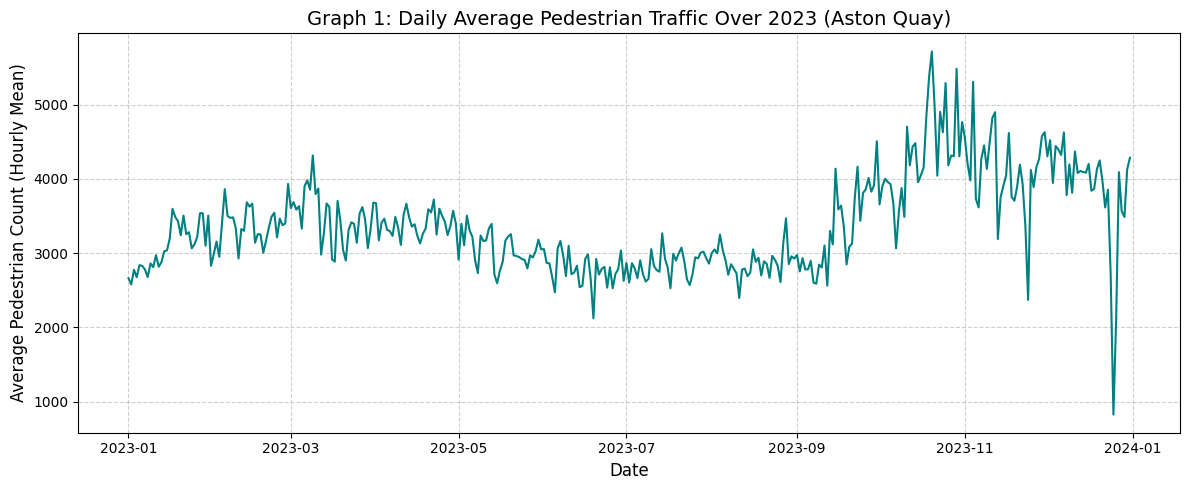

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Preprocessing: Convert 'Time' to datetime and set as index
df['Time'] = pd.to_datetime(df['Time'], format='%d/%m/%Y %H:%M')
df.set_index('Time', inplace=True)

# Define primary sample locations/columns for detailed analysis
loc_total = 'Aston Quay/Fitzgeralds'
loc_in = 'Aston Quay/Fitzgeralds IN'
loc_out = 'Aston Quay/Fitzgeralds OUT'

print("Daily Average Trend Over the Year")
plt.figure(figsize=(12, 5))
daily_traffic = df[loc_total].resample('D').mean()
plt.plot(
    daily_traffic.index,
    daily_traffic.values,
    color='teal',
    linewidth=1.5,
)
plt.title(
    'Graph 1: Daily Average Pedestrian Traffic Over 2023 (Aston Quay)',
    fontsize=14,
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Average Pedestrian Count (Hourly Mean)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

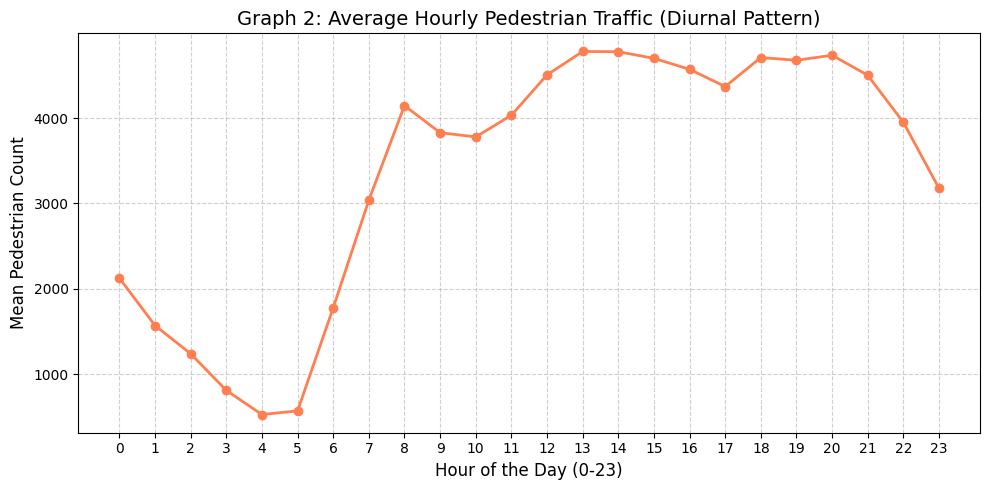

In [12]:
plt.figure(figsize=(10, 5))
hourly_avg = df.groupby(df.index.hour)[loc_total].mean()
plt.plot(
    hourly_avg.index,
    hourly_avg.values,
    marker='o',
    color='coral',
    linewidth=2,
)
plt.title(
    'Graph 2: Average Hourly Pedestrian Traffic (Diurnal Pattern)', fontsize=14
)
plt.xlabel('Hour of the Day (0-23)', fontsize=12)
plt.ylabel('Mean Pedestrian Count', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

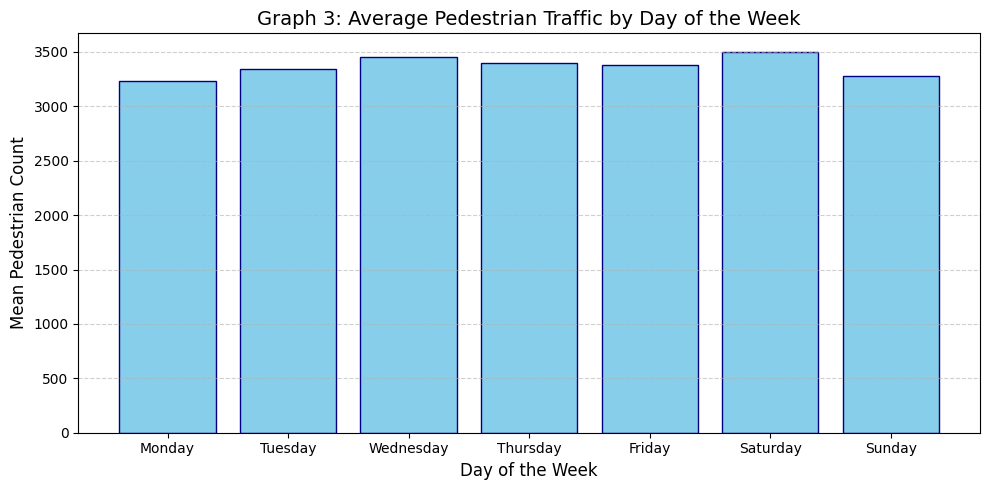

In [13]:
plt.figure(figsize=(10, 5))
df['DayOfWeek'] = df.index.day_name()
days_order = [
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday',
]
weekly_avg = df.groupby('DayOfWeek')[loc_total].mean().reindex(days_order)
plt.bar(weekly_avg.index, weekly_avg.values, color='skyblue', edgecolor='navy')
plt.title('Graph 3: Average Pedestrian Traffic by Day of the Week', fontsize=14)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Mean Pedestrian Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

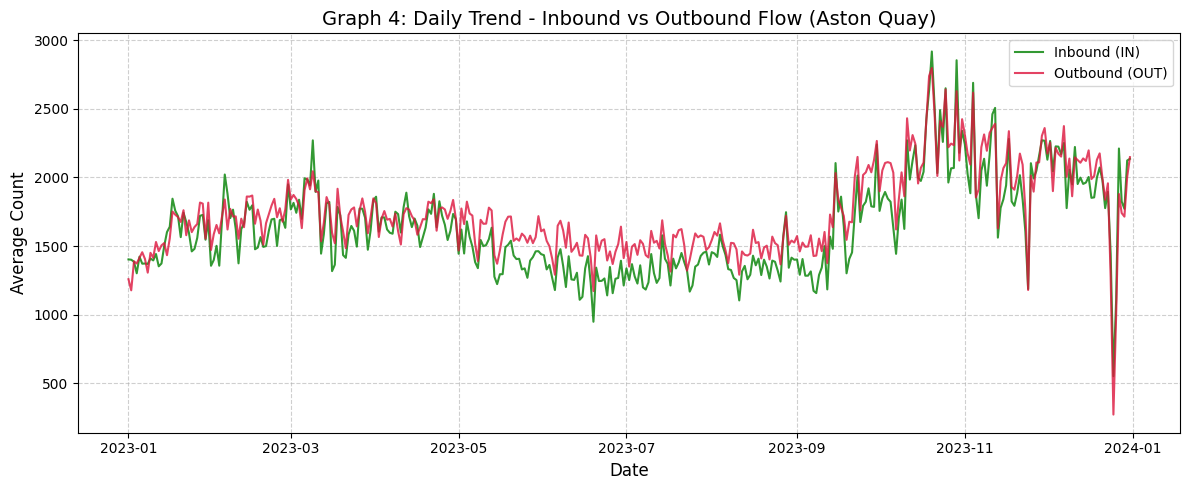

In [14]:
plt.figure(figsize=(12, 5))
in_daily = df[loc_in].resample('D').mean()
out_daily = df[loc_out].resample('D').mean()
plt.plot(
    in_daily.index,
    in_daily.values,
    label='Inbound (IN)',
    color='green',
    alpha=0.8,
)
plt.plot(
    out_daily.index,
    out_daily.values,
    label='Outbound (OUT)',
    color='crimson',
    alpha=0.8,
)
plt.title(
    'Graph 4: Daily Trend - Inbound vs Outbound Flow (Aston Quay)', fontsize=14
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Average Count', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3667/3764850135.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(monthly_data, labels=[m[:3] for m in months_order], patch_artist=True)


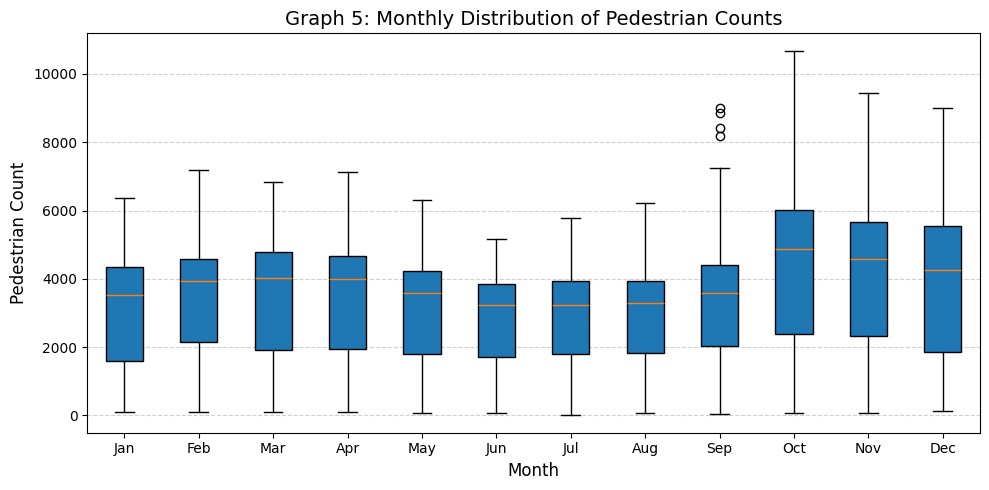

In [15]:
plt.figure(figsize=(10, 5))
df['Month'] = df.index.month_name()
months_order = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December',
]
monthly_data = [
    df[df['Month'] == m][loc_total].dropna().values for m in months_order
]
plt.boxplot(monthly_data, labels=[m[:3] for m in months_order], patch_artist=True)
plt.title('Graph 5: Monthly Distribution of Pedestrian Counts', fontsize=14)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Pedestrian Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

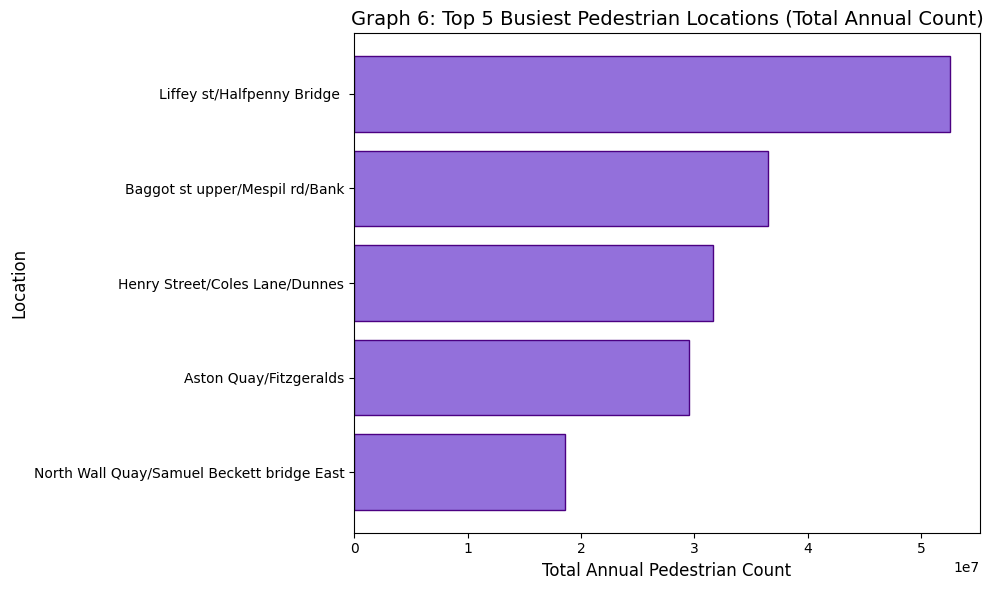

In [21]:
plt.figure(figsize=(10, 6))

exclude_cols = ['DayOfWeek', 'Month', loc_in, loc_out]
total_cols = [
    c
    for c in df.columns
    if c not in exclude_cols and 'IN' not in c and 'OUT' not in c
]
top_locations = df[total_cols].sum().nlargest(5)

plt.barh(
    top_locations.index,
    top_locations.values,
    color='mediumpurple',
    edgecolor='indigo',
)
plt.title(
    'Graph 6: Top 5 Busiest Pedestrian Locations (Total Annual Count)',
    fontsize=14,
)
plt.xlabel('Total Annual Pedestrian Count', fontsize=12)
plt.ylabel('Location', fontsize=12)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

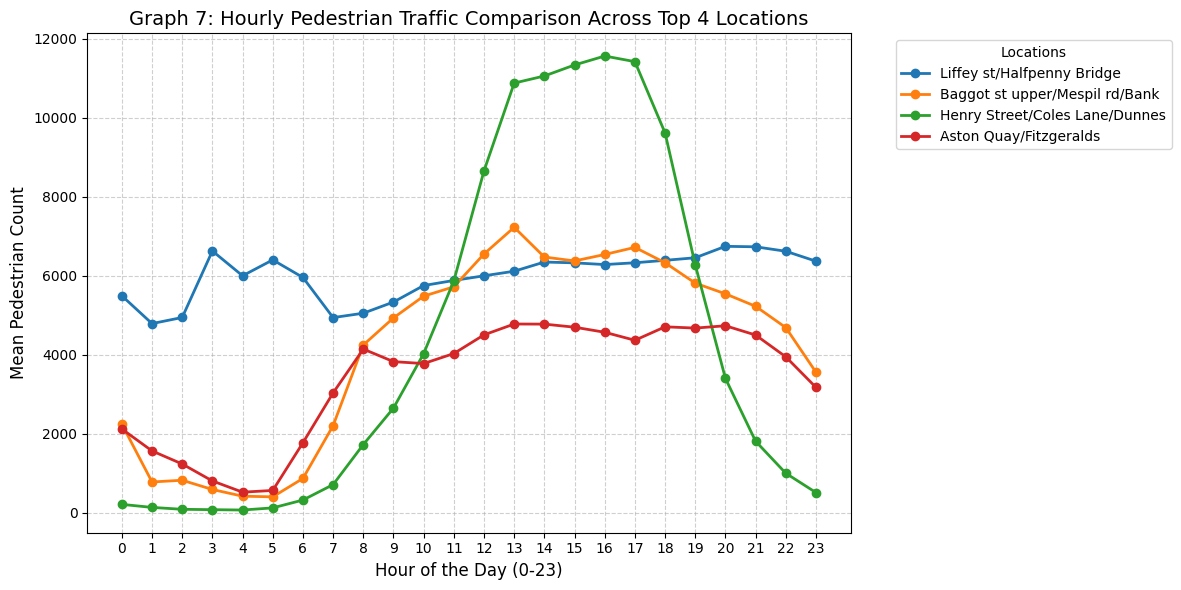

In [18]:
exclude_keywords = ['IN', 'OUT', 'DayOfWeek', 'Month']
total_cols = [
    c
    for c in df.columns
    if not any(keyword in c for keyword in exclude_keywords)
]
top_locations = df[total_cols].sum().nlargest(4).index.tolist()

plt.figure(figsize=(12, 6))

for loc in top_locations:
  hourly_avg = df.groupby(df.index.hour)[loc].mean()
  plt.plot(
      hourly_avg.index, hourly_avg.values, marker='o', linewidth=2, label=loc
  )

plt.title(
    'Graph 7: Hourly Pedestrian Traffic Comparison Across Top 4 Locations',
    fontsize=14,
)
plt.xlabel('Hour of the Day (0-23)', fontsize=12)
plt.ylabel('Mean Pedestrian Count', fontsize=12)
plt.xticks(range(0, 24))
plt.legend(title='Locations', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3667/2013372862.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_avg = df[loc].resample('M').mean()
/tmp/ipykernel_3667/2013372862.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_avg = df[loc].resample('M').mean()
/tmp/ipykernel_3667/2013372862.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_avg = df[loc].resample('M').mean()
/tmp/ipykernel_3667/2013372862.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_avg = df[loc].resample('M').mean()


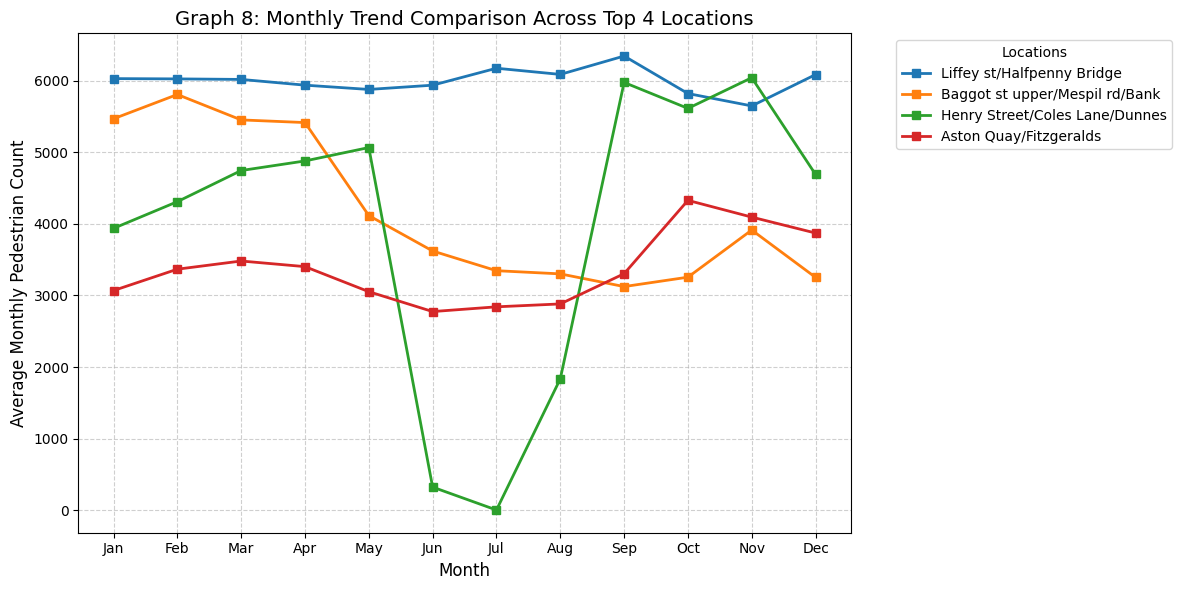

In [19]:
plt.figure(figsize=(12, 6))

for loc in top_locations:
  monthly_avg = df[loc].resample('M').mean()

  plt.plot(
      monthly_avg.index.strftime('%b'),
      monthly_avg.values,
      marker='s',
      linewidth=2,
      label=loc,
  )

plt.title(
    'Graph 8: Monthly Trend Comparison Across Top 4 Locations', fontsize=14
)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Monthly Pedestrian Count', fontsize=12)
plt.legend(title='Locations', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()